# I. DADOS E MÉTRICAS DE AVALIAÇÃO

## Download dos dados

In [ ]:
import io
import zipfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.io import arff
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay,
                             precision_recall_fscore_support)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

SEED = 42

pasta_projeto = Path.cwd()

if pasta_projeto.name != "01-metodos-ML-I":
    pasta_projeto = pasta_projeto / "01-metodos-ML-I"

pasta_dados = pasta_projeto / "dados"
pasta_dados.mkdir(exist_ok=True)

arquivo_cdc = pasta_dados / "cdc.csv"
arquivo_wine = pasta_dados / "WineQT.csv"

if not arquivo_cdc.exists():
    print("Baixando cdc.csv...")

    with urlopen("https://openml.org/data/v1/download/22124404/cdc_diabetes.arff") as resposta:
        dados_baixados = resposta.read()

    texto_cdc = dados_baixados.decode("utf-8")
    arquivo_em_memoria = io.StringIO(texto_cdc)
    registros, informacoes = arff.loadarff(arquivo_em_memoria)
        
    cdc = pd.DataFrame(registros)
    classes_cdc = cdc["Diabetes_binary"].str.decode("utf-8")
    cdc["Diabetes_binary"] = classes_cdc.astype(int)
    cdc.to_csv(arquivo_cdc, index=False)

print("cdc.csv baixado com sucesso!")

if not arquivo_wine.exists():
    print("Baixando WineQT.csv...")

    with urlopen("https://www.kaggle.com/api/v1/datasets/download/yasserh/wine-quality-dataset") as resposta:
        dados_baixados = resposta.read()

    arquivo_em_memoria = io.BytesIO(dados_baixados)
    with zipfile.ZipFile(arquivo_em_memoria) as pacote:
        with pacote.open("WineQT.csv") as arquivo:
            wine_baixado = pd.read_csv(arquivo)
    wine_baixado.to_csv(arquivo_wine, index=False)

print("WineQT.csv baixado com sucesso!")

cdc.csv baixado com sucesso!
WineQT.csv baixado com sucesso!


## CDC

Esse dataset tem informações de saúde relatadas por participantes de uma pesquisa, com e sem diabetes. Tem ifnormações sobre o estilo de vida (se a pessoa fuma, faz exercício físico), dados demográficos (idade e sexo), dados socioeconomicos (renda e grau de educaçao) e tbm indicadores de saúde relatados (pressão alta, colestoresol alto, histórico de doença cardíaca ou infarto e IMC) a classe é 0 para ausência de diabetes e 1 para pré-diabetes ou diabetes.

O dataset não possui valores nulos ou infinitos e os atributos de entrada já estão em formato numérico. Por isso, não foi necessário remover linhas ou colunas por valores ausentes, preencher esses valores ou aplicar one-hot encoding. Os registros duplicados foram removidos antes da divisão entre treino e teste.

In [ ]:
cdc = pd.read_csv(arquivo_cdc)
quantidade_original_cdc = len(cdc)
duplicados_cdc = int(cdc.duplicated().sum())
cdc = cdc.drop_duplicates().reset_index(drop=True)
print(f"CDC: {quantidade_original_cdc} registros originais. {duplicados_cdc} duplicados removidos. {len(cdc)} registros únicos.")
print("CDC:", cdc.shape)
display(cdc.head())

print("Resumo estatístico do CDC:")
resumo_cdc = cdc.describe()
resumo_cdc.loc["var"] = cdc.var(numeric_only=True)
display(resumo_cdc.round(3))

print("Quantidade de amostras por classe:")
print(cdc["Diabetes_binary"].value_counts())

X_cdc = cdc.drop(columns=["Diabetes_binary"])
y_cdc = cdc["Diabetes_binary"]

X_cdc_train, X_cdc_test, y_cdc_train, y_cdc_test = train_test_split(
    X_cdc, y_cdc, test_size=0.2, random_state=SEED, stratify=y_cdc
)

print()
print("Quantidade de amostras de treino:", X_cdc_train.shape[0])
print("Quantidade de amostras de teste:", X_cdc_test.shape[0])

print()
print(f"Chutar tudo como positivo (1) para o CDC daria uma acurácia de: {y_cdc_test.value_counts()[1] / y_cdc_test.shape[0]:.2%}")
print(f"Chutar tudo como negativo (0) para o CDC daria uma acurácia de: {y_cdc_test.value_counts()[0] / y_cdc_test.shape[0]:.2%}")

CDC: 253680 registros originais. 24206 duplicados removidos. 229474 registros únicos.
CDC: (229474, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0,0
1,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0,0
2,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0,0
3,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0,0
4,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0,0


Resumo estatístico do CDC:


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
count,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,...,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000,229474.000
mean,0.454,0.442,0.959,28.688,0.466,0.045,0.103,0.733,0.613,0.795,...,0.093,2.602,3.510,4.681,0.186,0.439,8.085,4.980,5.889,0.153
std,0.498,0.497,0.197,6.789,0.499,0.207,0.304,0.442,0.487,0.404,...,0.290,1.065,7.718,9.051,0.389,0.496,3.094,0.993,2.093,0.360
min,0.000,0.000,0.000,12.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,1.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,0.000
25%,0.000,0.000,1.000,24.000,0.000,0.000,0.000,0.000,0.000,1.000,...,0.000,2.000,0.000,0.000,0.000,0.000,6.000,4.000,4.000,0.000
50%,0.000,0.000,1.000,27.000,0.000,0.000,0.000,1.000,1.000,1.000,...,0.000,3.000,0.000,0.000,0.000,0.000,8.000,5.000,6.000,0.000
75%,1.000,1.000,1.000,32.000,1.000,0.000,0.000,1.000,1.000,1.000,...,0.000,3.000,2.000,4.000,0.000,1.000,10.000,6.000,8.000,0.000
max,1.000,1.000,1.000,98.000,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,5.000,30.000,30.000,1.000,1.000,13.000,6.000,8.000,1.000
var,0.248,0.247,0.039,46.093,0.249,0.043,0.093,0.196,0.237,0.163,...,0.084,1.134,59.562,81.918,0.151,0.246,9.576,0.986,4.380,0.130


Quantidade de amostras por classe:
Diabetes_binary
0    194377
1     35097
Name: count, dtype: int64

Quantidade de amostras de treino: 183579
Quantidade de amostras de teste: 45895

Chutar tudo como positivo (1) para o CDC daria uma acurácia de: 15.29%
Chutar tudo como negativo (0) para o CDC daria uma acurácia de: 84.71%


## Wine Quality

O dataset classifica a qualdidade do vinho com notas de 3 a 8 de acordo com as medidas de acidez, acuarm ph, alcool entre outras carcateristicas químicas.

Nota: Foi feita uma nova classificação com base na qualidade pois algumas notas de 3 a 8 tinham poucas amostras e ficava esparso demais. Algo comum para esse dataset na literatura é classificar em novas 3 classes. As novas clases são: 

- Ruim: nota menor ou igual a 4. 
- Médio: notas 5 e 6. 
- Bom: nota maior ou igual a 7.

O dataset não possui valores nulos ou infinitos e os atributos de entrada já estão em formato numérico. Por isso, não foi necessário remover linhas ou colunas por valores ausentes, preencher esses valores ou aplicar one-hot encoding. Os registros duplicados foram removidos antes da divisão entre treino e teste.

In [ ]:
def classes(nota):

    if nota <= 4:
        return "Ruim"
    
    elif nota <= 6:
        return "Médio"
    
    return "Bom"

wine = pd.read_csv(arquivo_wine).drop(columns=["Id"])
quantidade_original_wine = len(wine)
duplicados_wine = int(wine.duplicated().sum())
wine = wine.drop_duplicates().reset_index(drop=True)
print(f"Wine: {quantidade_original_wine} registros originais. {duplicados_wine} duplicados removidos. {len(wine)} registros únicos.")
wine["classe"] = wine["quality"].apply(classes)

display(wine.head())

print("Resumo estatístico do Wine:")
resumo_wine = wine.describe()
resumo_wine.loc["var"] = wine.var(numeric_only=True)
display(resumo_wine.round(3))

print("Quantidade de amostras por classe:")
print(wine["classe"].value_counts())

X_wine = wine.drop(columns=["quality", "classe"])
y_wine = wine["classe"]

X_wine_train, X_wine_test, y_wine_train, y_wine_test = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=SEED, stratify=y_wine
)

print()
print("Quantidade de amostras de treino:", X_wine_train.shape[0])
print("Quantidade de amostras de teste:", X_wine_test.shape[0])

print()
print(f"Chutar tudo como 'Ruim' para o Wine daria uma acurácia de: {y_wine_test.value_counts()['Ruim'] / y_wine_test.shape[0]:.2%}")
print(f"Chutar tudo como 'Médio' para o Wine daria uma acurácia de: {y_wine_test.value_counts()['Médio'] / y_wine_test.shape[0]:.2%}")
print(f"Chutar tudo como 'Bom' para o Wine daria uma acurácia de: {y_wine_test.value_counts()['Bom'] / y_wine_test.shape[0]:.2%}")

Wine: 1143 registros originais. 125 duplicados removidos. 1018 registros únicos.


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,classe
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Médio
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Médio
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Médio
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Médio
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,Médio


Resumo estatístico do Wine:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000,1018.000
mean,8.289,0.534,0.269,2.524,0.087,15.649,46.326,0.997,3.312,0.657,10.452,5.641
std,1.741,0.183,0.196,1.315,0.049,10.177,33.124,0.002,0.158,0.168,1.095,0.812
min,4.600,0.120,0.000,0.900,0.012,1.000,6.000,0.990,2.740,0.330,8.400,3.000
25%,7.100,0.390,0.090,1.900,0.070,7.000,21.000,0.996,3.210,0.550,9.500,5.000
50%,7.900,0.520,0.250,2.200,0.079,13.000,38.000,0.997,3.310,0.620,10.200,6.000
75%,9.100,0.645,0.420,2.600,0.090,21.000,62.000,0.998,3.400,0.720,11.200,6.000
max,15.900,1.580,1.000,15.500,0.611,68.000,289.000,1.004,4.010,2.000,14.900,8.000
var,3.032,0.034,0.039,1.729,0.002,103.562,1097.168,0.000,0.025,0.028,1.199,0.659


Quantidade de amostras por classe:
classe
Médio    842
Bom      137
Ruim      39
Name: count, dtype: int64

Quantidade de amostras de treino: 814
Quantidade de amostras de teste: 204

Chutar tudo como 'Ruim' para o Wine daria uma acurácia de: 3.92%
Chutar tudo como 'Médio' para o Wine daria uma acurácia de: 82.84%
Chutar tudo como 'Bom' para o Wine daria uma acurácia de: 13.24%


## Por que a acurácia isolada pode ser problemática?

Porque os conjuntos são desbalanceados, o que faz com que se o modelo prever sempre a classe majoritária ele já pode alcançar acurácia alta sem acertar nunca as outras classes. O que não é um modelo bom, mesmo o valor de acurácia sendo alto, por isso existe a matriz de confusão que nos permite calcular outras métricas como precisão, recall e f1.


## Validação cruzada


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# II. MÁQUINA DE VETORES DE SUPORTE

## A. Sobre o método

A SVM linear aprende uma reta (ou hiperplano quando tem mais dimensões) no formato `w · x + b = 0` que age como fronteira para separar duas classes. Busca-se a maior margem possível, ou seja, a maior distância entre a fronteira e os exemplos mais próximos de cada lado, esses exemplos mais próximos são denominados vetores de suporte. Durante o treino são aprendidos os pesos `w` e a constante `b`, que determinam a reta/hiperplano. O método é sensível a escala porque a escala das colunas influencia a distância e a penalização dos pesos e a distância é facilmente influenciada por medidas em escalas diferentes.


## B. Implementação


In [ ]:
grades_svm = {
    "CDC": {
        "linear": {"svm__C": [0.01, 0.1, 1.0, 10.0]},
        "rbf": {
            "svm__C": [0.1, 1.0, 10.0],
            "svm__gamma": [0.01, "scale", 0.1],
        },
    },
    "Wine": {
        "linear": {"svm__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
        "rbf": {
            "svm__C": [0.1, 1.0, 10.0, 100.0],
            "svm__gamma": [0.001, 0.01, "scale", 0.1, 1.0],
        },
    },
}

# O CDC usa uma amostra estratificada na busca.
X_cdc_busca, _, y_cdc_busca, _ = train_test_split(
    X_cdc_train, y_cdc_train, train_size=5000,
    stratify=y_cdc_train, random_state=SEED
)

# O Wine usa todo o treino na busca.
dados_busca = {
    "CDC": (X_cdc_busca, y_cdc_busca),
    "Wine": (X_wine_train, y_wine_train),
}

dados_svm = {
    "CDC": (X_cdc_train, y_cdc_train, X_cdc_test, y_cdc_test, X_cdc, y_cdc),
    "Wine": (X_wine_train, y_wine_train, X_wine_test, y_wine_test, X_wine, y_wine),
}

buscas_svm = {}

for nome in ["CDC", "Wine"]:
    
    X_treino = dados_svm[nome][0]
    y_treino = dados_svm[nome][1]

    X_busca = dados_busca[nome][0]
    y_busca = dados_busca[nome][1]
    
    print(f"{nome}: busca em {len(y_busca)} exemplos. Ajuste final em {len(y_treino)}.")
    print()

    for kernel in ["linear", "rbf"]:

        print(f"Ajustando {nome}: {kernel}", flush=True)
        modelo = Pipeline([
            ("escala", StandardScaler()),
            ("svm", SVC(kernel=kernel, class_weight="balanced", cache_size=512)),
        ])

        grade = grades_svm[nome][kernel]
        busca = GridSearchCV(
            modelo, grade, scoring="f1_macro", cv=cv,
            verbose=1, error_score="raise"
        )
        busca.fit(X_busca, y_busca)

        # Reajusta o pipeline inteiro, inclusive a escala, usando todo o treino.
        busca.best_estimator_.fit(X_treino, y_treino)
        chave = (nome, kernel)
        buscas_svm[chave] = busca

        print()
        print("Melhores parâmetros:", busca.best_params_)
        resultados_folds = busca.cv_results_
        linhas_busca = []

        for candidato in range(len(resultados_folds["params"])):
            notas_folds = []
            for fold in range(cv.n_splits):
                coluna_fold = f"split{fold}_test_score"
                nota = resultados_folds[coluna_fold][candidato]
                notas_folds.append(nota)

            media = np.mean(notas_folds)
            desvio = np.std(notas_folds, ddof=1)
            linhas_busca.append({
                "hiperparâmetros": resultados_folds["params"][candidato],
                "média_validação": media,
                "desvio_validação": desvio,
            })

        tabela_busca = pd.DataFrame(linhas_busca)
        tabela_busca = tabela_busca.sort_values("média_validação", ascending=False)
        display(tabela_busca.round(4))
        print()

CDC: busca em 5000 exemplos. Ajuste final em 183579.

Ajustando CDC: linear
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Melhores parâmetros: {'svm__C': 0.1}


,hiperparâmetros,média_validação,desvio_validação
1,{'svm__C': 0.1},0.6140,0.0070
2,{'svm__C': 1.0},0.6135,0.0064
3,{'svm__C': 10.0},0.6135,0.0064
0,{'svm__C': 0.01},0.6118,0.0086



Ajustando CDC: rbf
Fitting 5 folds for each of 9 candidates, totalling 45 fits

Melhores parâmetros: {'svm__C': 1.0, 'svm__gamma': 'scale'}


,hiperparâmetros,média_validação,desvio_validação
4,"{'svm__C': 1.0, 'svm__gamma': 'scale'}",0.6264,0.0082
6,"{'svm__C': 10.0, 'svm__gamma': 0.01}",0.6215,0.0100
5,"{'svm__C': 1.0, 'svm__gamma': 0.1}",0.6193,0.0110
3,"{'svm__C': 1.0, 'svm__gamma': 0.01}",0.6171,0.0057
0,"{'svm__C': 0.1, 'svm__gamma': 0.01}",0.6113,0.0059
1,"{'svm__C': 0.1, 'svm__gamma': 'scale'}",0.6036,0.0100
7,"{'svm__C': 10.0, 'svm__gamma': 'scale'}",0.6034,0.0143
8,"{'svm__C': 10.0, 'svm__gamma': 0.1}",0.5819,0.0120
2,"{'svm__C': 0.1, 'svm__gamma': 0.1}",0.5753,0.0105



Wine: busca em 814 exemplos. Ajuste final em 814.

Ajustando Wine: linear
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Melhores parâmetros: {'svm__C': 100.0}


,hiperparâmetros,média_validação,desvio_validação
4,{'svm__C': 100.0},0.4522,0.0189
2,{'svm__C': 1.0},0.4515,0.0316
3,{'svm__C': 10.0},0.4508,0.0192
1,{'svm__C': 0.1},0.4428,0.0296
0,{'svm__C': 0.01},0.4332,0.0323



Ajustando Wine: rbf
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Melhores parâmetros: {'svm__C': 100.0, 'svm__gamma': 0.01}


,hiperparâmetros,média_validação,desvio_validação
16,"{'svm__C': 100.0, 'svm__gamma': 0.01}",0.4800,0.0303
11,"{'svm__C': 10.0, 'svm__gamma': 0.01}",0.4747,0.0411
8,"{'svm__C': 1.0, 'svm__gamma': 0.1}",0.4731,0.0307
7,"{'svm__C': 1.0, 'svm__gamma': 'scale'}",0.4729,0.0342
13,"{'svm__C': 10.0, 'svm__gamma': 0.1}",0.4719,0.0334
12,"{'svm__C': 10.0, 'svm__gamma': 'scale'}",0.4698,0.0273
18,"{'svm__C': 100.0, 'svm__gamma': 0.1}",0.4647,0.0446
17,"{'svm__C': 100.0, 'svm__gamma': 'scale'}",0.4647,0.0405
1,"{'svm__C': 0.1, 'svm__gamma': 0.01}",0.4632,0.0420
15,"{'svm__C': 100.0, 'svm__gamma': 0.001}",0.4571,0.0303


## C. Experimento

,dataset,kernel,acurácia,precisão macro,revocação macro,F1 macro
0,CDC,linear,0.6971,0.6269,0.7330,0.6171
1,CDC,rbf,0.7014,0.6289,0.7358,0.6207
2,Wine,linear,0.5784,0.4692,0.6594,0.4565
3,Wine,rbf,0.6961,0.4954,0.6567,0.5175



CDC linear


,precision,recall,f1-score,support
0,0.9460,0.6813,0.7921,38876.0000
1,0.3078,0.7847,0.4421,7019.0000
accuracy,0.6971,0.6971,0.6971,0.6971
macro avg,0.6269,0.7330,0.6171,45895.0000
weighted avg,0.8484,0.6971,0.7386,45895.0000



CDC rbf


,precision,recall,f1-score,support
0,0.9465,0.6863,0.7957,38876.0000
1,0.3113,0.7853,0.4458,7019.0000
accuracy,0.7014,0.7014,0.7014,0.7014
macro avg,0.6289,0.7358,0.6207,45895.0000
weighted avg,0.8494,0.7014,0.7421,45895.0000



Wine linear


,precision,recall,f1-score,support
Bom,0.3607,0.8148,0.5000,27.0000
Médio,0.9381,0.5385,0.6842,169.0000
Ruim,0.1087,0.6250,0.1852,8.0000
accuracy,0.5784,0.5784,0.5784,0.5784
macro avg,0.4692,0.6594,0.4565,204.0000
weighted avg,0.8292,0.5784,0.6403,204.0000



Wine rbf


,precision,recall,f1-score,support
Bom,0.3889,0.7778,0.5185,27.0000
Médio,0.9435,0.6923,0.7986,169.0000
Ruim,0.1538,0.5000,0.2353,8.0000
accuracy,0.6961,0.6961,0.6961,0.6961
macro avg,0.4954,0.6567,0.5175,204.0000
weighted avg,0.8392,0.6961,0.7395,204.0000


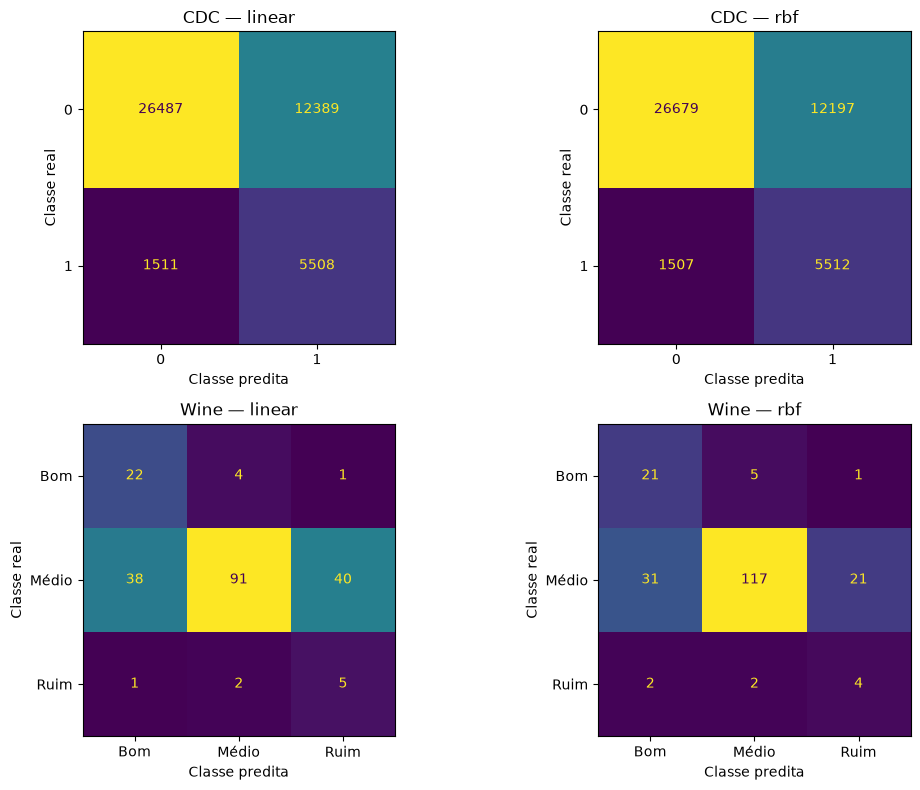

In [ ]:
resultados_svm = []
predicoes_svm = {}

for nome in ["CDC", "Wine"]:
    
    X_teste = dados_svm[nome][2]
    y_teste = dados_svm[nome][3]

    for kernel in ["linear", "rbf"]:
        chave = (nome, kernel)
        busca = buscas_svm[chave]
        y_pred = busca.predict(X_teste)

        precisao, revocacao, f1, suporte = precision_recall_fscore_support(
            y_teste, y_pred, average="macro", zero_division=0
        )

        resultados_svm.append({
            "dataset": nome,
            "kernel": kernel,
            "acurácia": accuracy_score(y_teste, y_pred),
            "precisão macro": precisao,
            "revocação macro": revocacao,
            "F1 macro": f1,
        })
        predicoes_svm[chave] = y_pred

tabela_svm = pd.DataFrame(resultados_svm)
display(tabela_svm.round(4))
print()

fig, eixos = plt.subplots(2, 2, figsize=(11, 8), squeeze=False)

for linha, nome in enumerate(["CDC", "Wine"]):
    y_real = dados_svm[nome][3]

    for coluna, kernel in enumerate(["linear", "rbf"]):
        chave = (nome, kernel)
        busca = buscas_svm[chave]
        eixo = eixos[linha, coluna]
        labels = busca.classes_
        y_pred = predicoes_svm[chave]

        ConfusionMatrixDisplay.from_predictions(
            y_real, y_pred, labels=labels, ax=eixo, colorbar=False
        )
        eixo.set_title(f"{nome} — {kernel}")
        eixo.set_xlabel("Classe predita")
        eixo.set_ylabel("Classe real")

        print(nome, kernel)
        relatorio = classification_report(
            y_real, y_pred, labels=labels, output_dict=True, zero_division=0
        )
        tabela_relatorio = pd.DataFrame(relatorio).T
        display(tabela_relatorio.round(4))
        print()

fig.tight_layout()
plt.show()

### Discussão dos resultados

No CDC, a SVM RBF teve acurácia de 0,7014 e F1 macro de 0,6207, enquanto a linear teve acurácia de 0,6971 e F1 macro de 0,6171. Os dois modelos conseguiram encontrar a maioria dos casos da classe 1, mas tiveram precisão baixa nessa classe, ou seja, encontraram a maioria das pessoas que estavam doentes, mas, ao mesmo tempo, os modelos falaram que muitas pessoas sem diabetes estavam doentes (falsos positivos).

No Wine, a diferença foi maior. O RBF teve acurácia de 0,6961 e F1 macro de 0,5175, enquanto o linear teve acurácia de 0,5784 e F1 macro de 0,4565. A classe Ruim teve o pior resultado, o que é esperado, já que tem poucas amostras. 

Portanto, a versão com núcleo gaussiano da SVM foi melhor em ambos os casos.

### Fronteiras de decisão — dois atributos


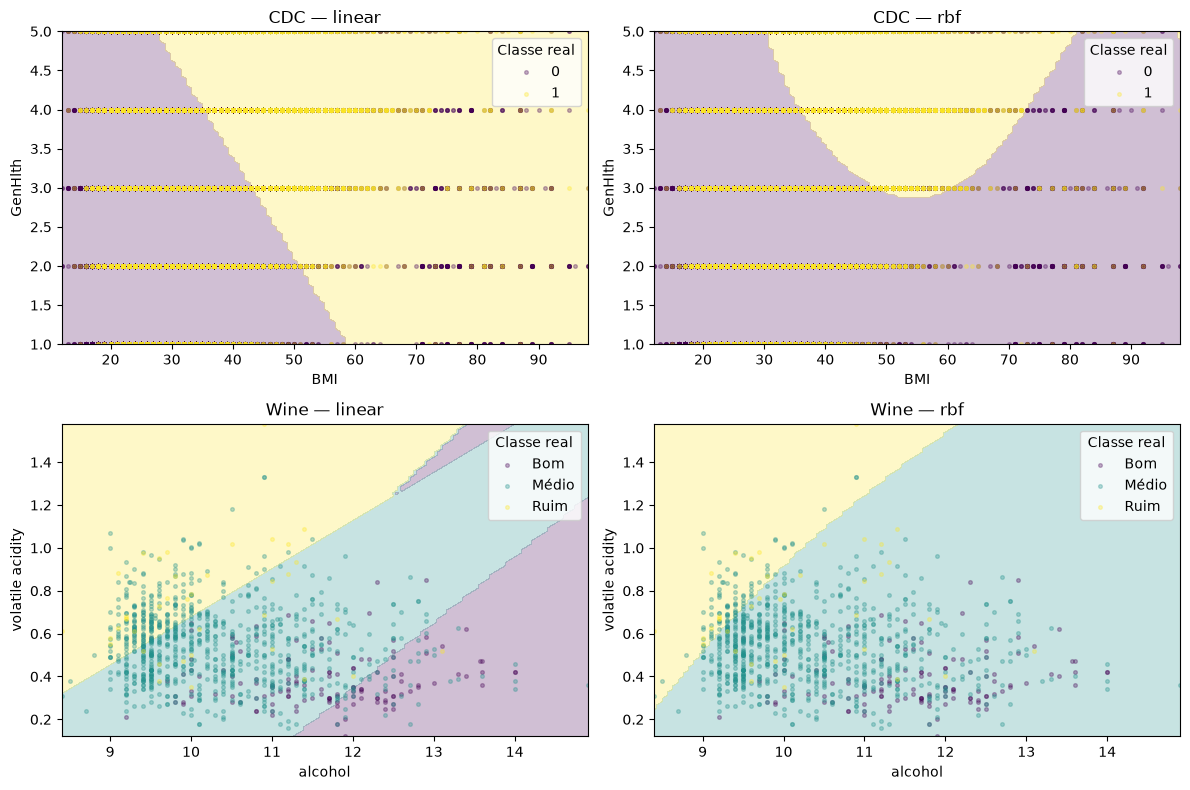

In [ ]:
atributos_fronteira = {
    "CDC": ["BMI", "GenHlth"],
    "Wine": ["alcohol", "volatile acidity"],
}

fig, eixos = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)

for linha, nome in enumerate(["CDC", "Wine"]):
    
    X_treino = dados_svm[nome][0]
    X_total = dados_svm[nome][4]
    y_total = dados_svm[nome][5]
    atributo_x = atributos_fronteira[nome][0]
    atributo_y = atributos_fronteira[nome][1]

    valores_x = np.linspace(X_total[atributo_x].min(), X_total[atributo_x].max(), 100)
    valores_y = np.linspace(X_total[atributo_y].min(), X_total[atributo_y].max(), 100)
    xx, yy = np.meshgrid(valores_x, valores_y)

    # Cada linha da grade começa com as medianas dos atributos do treino.
    medianas = X_treino.median()
    grade = pd.DataFrame(index=range(xx.size))

    for atributo in X_treino.columns:
        grade[atributo] = medianas[atributo]
        
    grade[atributo_x] = xx.ravel()
    grade[atributo_y] = yy.ravel()

    codificador = LabelEncoder()
    codificador.fit(y_total)
    quantidade_classes = len(codificador.classes_)
    niveis = np.arange(quantidade_classes + 1) - 0.5

    for coluna, kernel in enumerate(["linear", "rbf"]):
        chave = (nome, kernel)
        busca = buscas_svm[chave]
        eixo = eixos[linha, coluna]

        predicoes_grade = busca.predict(grade)
        classes_grade = codificador.transform(predicoes_grade)
        zz = classes_grade.reshape(xx.shape)
        eixo.contourf(
            xx, yy, zz, levels=niveis, cmap="viridis", alpha=0.25,
            vmin=0, vmax=quantidade_classes - 1
        )

        for i, classe in enumerate(codificador.classes_):
            mascara = y_total == classe
            cor = plt.cm.viridis(i / max(quantidade_classes - 1, 1))
            pontos_x = X_total.loc[mascara, atributo_x]
            pontos_y = X_total.loc[mascara, atributo_y]
            eixo.scatter(
                pontos_x, pontos_y, color=cor, label=str(classe),
                s=7, alpha=0.3, rasterized=True
            )

        eixo.set_title(f"{nome} — {kernel}")
        eixo.set_xlabel(atributo_x)
        eixo.set_ylabel(atributo_y)
        eixo.legend(title="Classe real")

fig.tight_layout()
plt.show()

No CDC, foram escolhidos `BMI` e `GenHlth` porque, entre as combinações observadas, foram os atributos que deixaram mais clara a tendência entre as classes. O modelo usa todos os atributos, mas no gráfico somente esses dois variam e os outros ficam na mediana do treino. A mistura dos pontos mostra que mesmo sendo as melhores opções `BMI` e `GenHlth` sozinhos não separam bem as classes.

No Wine, foram escolhidos `alcohol` e `volatile acidity` porque essa combinação mostrou melhor a tendência de vinhos com mais álcool e menor acidez volátil receberem classificações melhores. O modelo usa todos os atributos, mas no gráfico somente esses dois variam e os outros ficam na mediana do treino. A fronteira linear cria faixas para as três classes, enquanto a RBF deixa a maior parte desse corte como Médio e o resto como Ruim. A classe Bom não aparece no fundo da RBF apenas nesse corte, mas o modelo completo consegue prever essa classe usando os valores dos outros atributos.

# III. REGRESSÃO LOGÍSTICA

## A. Sobre o método

A regressão logística é um classificador linear que calcula uma pontuação no formato `z = w · x + b` e usa a função sigmoide para transformar o resultado em uma probabilidade entre 0 e 1. Durante o treino são ajustados os pesos `w` e a constante `b` minimizando a log-loss, que aumenta o erro quando a previsão fica distante da classe correta. Para mais de duas classes é usado o softmax, que transforma a pontuação de cada classe em probabilidades que somam 1, normalizando cada valor. A temperatura controla como essas probabilidades ficam distribuídas, valores menores deixam o resultado mais concentrado na classe com maior pontuação, enquanto valores maiores deixam as probabilidades mais distribuídas entre as classes.


## B. Implementação


In [ ]:
dados_logistica = {
    "CDC": (X_cdc_train, y_cdc_train, X_cdc_test, y_cdc_test, X_cdc, y_cdc),
    "Wine": (X_wine_train, y_wine_train, X_wine_test, y_wine_test, X_wine, y_wine),
}

valores_C_logistica = [0.01, 0.1, 1.0, 10.0, 100.0]
buscas_logistica = {}

for nome in ["CDC", "Wine"]:

    X_treino = dados_logistica[nome][0]
    y_treino = dados_logistica[nome][1]

    X_busca = dados_busca[nome][0]
    y_busca = dados_busca[nome][1]
    
    print(f"{nome}: busca em {len(y_busca)} exemplos. Ajuste final em {len(y_treino)}.")
    print()

    modelo = Pipeline([
        ("escala", StandardScaler()),
        ("logistica", LogisticRegression(
            class_weight="balanced", solver="lbfgs", max_iter=5000
        )),
    ])

    busca = GridSearchCV(
        modelo, {"logistica__C": valores_C_logistica}, scoring="f1_macro",
        cv=cv,
        verbose=1, error_score="raise"
    )

    busca.fit(X_busca, y_busca)

    # Reajusta o pipeline inteiro, inclusive a escala, usando todo o treino.
    busca.best_estimator_.fit(X_treino, y_treino)
    buscas_logistica[nome] = busca

    print()
    print("Melhores parâmetros:", busca.best_params_)
    resultados_folds = busca.cv_results_
    linhas_busca = []

    for candidato in range(len(resultados_folds["params"])):
        notas_folds = []
        for fold in range(cv.n_splits):
            coluna_fold = f"split{fold}_test_score"
            nota = resultados_folds[coluna_fold][candidato]
            notas_folds.append(nota)

        media = np.mean(notas_folds)
        desvio = np.std(notas_folds, ddof=1)
        linhas_busca.append({
            "hiperparâmetros": resultados_folds["params"][candidato],
            "média_validação": media,
            "desvio_validação": desvio,
        })

    tabela_busca = pd.DataFrame(linhas_busca)
    tabela_busca = tabela_busca.sort_values("média_validação", ascending=False)
    display(tabela_busca.round(4))
    print()

CDC: busca em 5000 exemplos. Ajuste final em 183579.

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Melhores parâmetros: {'logistica__C': 0.01}


,hiperparâmetros,média_validação,desvio_validação
0,{'logistica__C': 0.01},0.6252,0.0061
1,{'logistica__C': 0.1},0.6238,0.0071
3,{'logistica__C': 10.0},0.6233,0.0081
4,{'logistica__C': 100.0},0.6233,0.0081
2,{'logistica__C': 1.0},0.6230,0.0080



Wine: busca em 814 exemplos. Ajuste final em 814.

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Melhores parâmetros: {'logistica__C': 1.0}


,hiperparâmetros,média_validação,desvio_validação
2,{'logistica__C': 1.0},0.4546,0.0223
1,{'logistica__C': 0.1},0.4508,0.0211
3,{'logistica__C': 10.0},0.4501,0.0221
4,{'logistica__C': 100.0},0.4501,0.0221
0,{'logistica__C': 0.01},0.4378,0.0363


## C. Experimento


,dataset,acurácia,precisão macro,revocação macro,F1 macro
0,CDC,0.7141,0.6300,0.7327,0.6277
1,Wine,0.5539,0.4741,0.6893,0.4519



CDC


,precision,recall,f1-score,support
0,0.9420,0.7059,0.8071,38876.0000
1,0.3180,0.7594,0.4483,7019.0000
accuracy,0.7141,0.7141,0.7141,0.7141
macro avg,0.6300,0.7327,0.6277,45895.0000
weighted avg,0.8466,0.7141,0.7522,45895.0000



Wine


,precision,recall,f1-score,support
Bom,0.3667,0.8148,0.5057,27.0000
Médio,0.9444,0.5030,0.6564,169.0000
Ruim,0.1111,0.7500,0.1935,8.0000
accuracy,0.5539,0.5539,0.5539,0.5539
macro avg,0.4741,0.6893,0.4519,204.0000
weighted avg,0.8353,0.5539,0.6183,204.0000


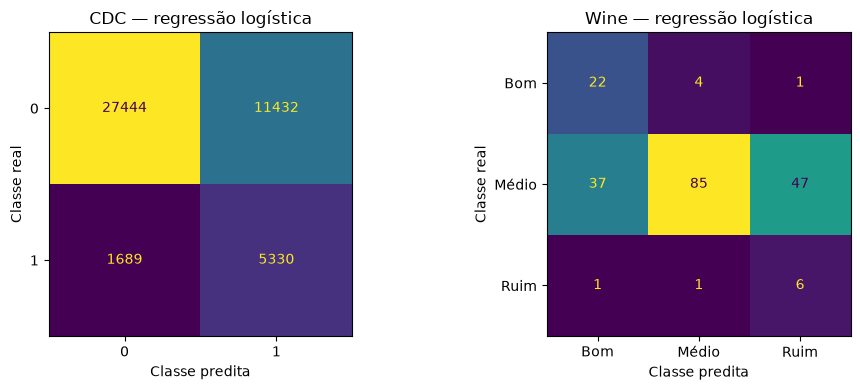

In [ ]:
resultados_logistica = []
predicoes_logistica = {}

for nome in ["CDC", "Wine"]:
    
    busca = buscas_logistica[nome]
    X_teste = dados_logistica[nome][2]
    y_teste = dados_logistica[nome][3]
    y_pred = busca.predict(X_teste)

    precisao, revocacao, f1, suporte = precision_recall_fscore_support(
        y_teste, y_pred, average="macro", zero_division=0
    )
    resultados_logistica.append({
        "dataset": nome,
        "acurácia": accuracy_score(y_teste, y_pred),
        "precisão macro": precisao,
        "revocação macro": revocacao,
        "F1 macro": f1,
    })
    predicoes_logistica[nome] = y_pred

tabela_logistica = pd.DataFrame(resultados_logistica)
display(tabela_logistica.round(4))
print()

fig, eixos = plt.subplots(1, 2, figsize=(10, 4), squeeze=False)

for coluna, nome in enumerate(["CDC", "Wine"]):
    busca = buscas_logistica[nome]
    eixo = eixos[0, coluna]
    y_real = dados_logistica[nome][3]
    y_pred = predicoes_logistica[nome]
    labels = busca.classes_

    ConfusionMatrixDisplay.from_predictions(
        y_real, y_pred, labels=labels, ax=eixo, colorbar=False
    )
    eixo.set_title(f"{nome} — regressão logística")
    eixo.set_xlabel("Classe predita")
    eixo.set_ylabel("Classe real")

    print(nome)
    relatorio = classification_report(
        y_real, y_pred, labels=labels, output_dict=True, zero_division=0
    )
    tabela_relatorio = pd.DataFrame(relatorio).T
    display(tabela_relatorio.round(4))
    print()

fig.tight_layout()
plt.show()

### Discussão dos resultados

No CDC, a regressão logística teve acurácia de 0,7141 e F1 macro de 0,6277. A classe 1 teve revocação de 0,7594, mas precisão de 0,3180, mostrando que a maioria dos casos positivos foi encontrada, mas também foram gerados muitos falsos positivos. 

No Wine, a acurácia foi de 0,5539 e o F1 macro de 0,4519. As classes Bom e Ruim tiveram uma revocação boa, mas precisão baixa, principalmente a classe Ruim que tem poucas amostras.


### Fronteira de decisão — dois atributos


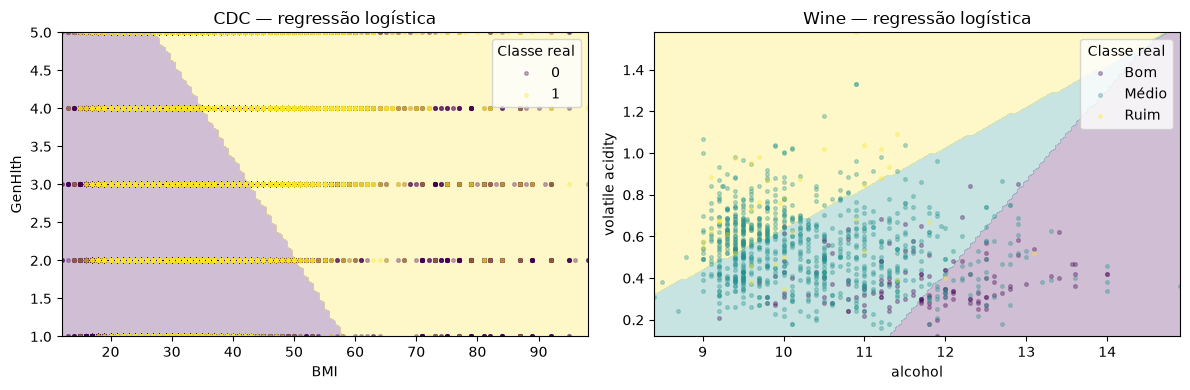

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), squeeze=False)

for coluna, nome in enumerate(["CDC", "Wine"]):
    busca = buscas_logistica[nome]
    eixo = eixos[0, coluna]
    X_treino = dados_logistica[nome][0]
    X_total = dados_logistica[nome][4]
    y_total = dados_logistica[nome][5]
    atributo_x = atributos_fronteira[nome][0]
    atributo_y = atributos_fronteira[nome][1]

    valores_x = np.linspace(X_total[atributo_x].min(), X_total[atributo_x].max(), 100)
    valores_y = np.linspace(X_total[atributo_y].min(), X_total[atributo_y].max(), 100)
    xx, yy = np.meshgrid(valores_x, valores_y)

    # Somente os dois atributos do grafico variam; os outros ficam na mediana.
    medianas = X_treino.median()
    grade = pd.DataFrame(index=range(xx.size))

    for atributo in X_treino.columns:
        grade[atributo] = medianas[atributo]
        
    grade[atributo_x] = xx.ravel()
    grade[atributo_y] = yy.ravel()

    codificador = LabelEncoder()
    codificador.fit(y_total)
    quantidade_classes = len(codificador.classes_)
    niveis = np.arange(quantidade_classes + 1) - 0.5
    predicoes_grade = busca.predict(grade)
    classes_grade = codificador.transform(predicoes_grade)
    zz = classes_grade.reshape(xx.shape)

    eixo.contourf(
        xx, yy, zz, levels=niveis, cmap="viridis", alpha=0.25,
        vmin=0, vmax=quantidade_classes - 1
    )
    for i, classe in enumerate(codificador.classes_):
        mascara = y_total == classe
        cor = plt.cm.viridis(i / max(quantidade_classes - 1, 1))
        pontos_x = X_total.loc[mascara, atributo_x]
        pontos_y = X_total.loc[mascara, atributo_y]
        eixo.scatter(
            pontos_x, pontos_y, color=cor, label=str(classe),
            s=7, alpha=0.3, rasterized=True
        )

    eixo.set_title(f"{nome} — regressão logística")
    eixo.set_xlabel(atributo_x)
    eixo.set_ylabel(atributo_y)
    eixo.legend(title="Classe real")

fig.tight_layout()
plt.show()

No CDC, foram mantidos `BMI` e `GenHlth` porque essa combinação deixou mais clara a tendência entre os atributos e a classe. O modelo usa todos os atributos, mas no gráfico somente esses dois variam e os outros ficam na mediana do treino. A divisão é feita por uma linha reta, e a mistura dos pontos mostra que `BMI` e `GenHlth` sozinhos não separam bem as classes.

No Wine, foram mantidos `alcohol` e `volatile acidity` porque foram os dois atributos que mostraram melhor a mudança entre as classes. O modelo usa todos os atributos, mas no gráfico somente esses dois variam e os outros ficam na mediana do treino. A concklusão é que `alcohol` e `volatile acidity` sozinhos não separam bem as classes.

# IV. k VIZINHOS MAIS PRÓXIMOS

## A. Sobre o método

O kNN classifica um exemplo olhando os `k` exemplos mais próximos e contando quantos desses vizinhos são de cada classe, a classe que tiver mais pontos é escolhida como a classe desse exemplo. Quando duas ou mais classes recebem o mesmo número de votos, o kNN escolhe classe com menor rótulo em ordem crescente (0 antes de 1 e 'A' antes de 'B'). Usar um `k` ímpar reduz a chance de empate quando existem duas classes, mas não impede o empate quando existem mais classes. O método não tem uma fase de treino porque apenas armazena os dados, com isso o trabalho fica para a predição, quando é necessário calcular a distância entre o novo exemplo e TODOS os exemplos do treino. O método é sensível a escala porque atributos com valores maiores podem dominar o cálculo da distância, por isso os dados são normalizados. A maldição da dimensionalidade acontece porque com muitos atributos as distâncias ficam menos diferentes e os vizinhos deixam de representar tão bem os exemplos parecidos, além de aumentar o custo da predição.


## B. Implementação


In [ ]:
dados_knn = {
    "CDC": (X_cdc_train, y_cdc_train, X_cdc_test, y_cdc_test),
    "Wine": (X_wine_train, y_wine_train, X_wine_test, y_wine_test),
}

valores_k = [1, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31]
buscas_knn = {}

for nome in ["CDC", "Wine"]:

    X_treino = dados_knn[nome][0]
    y_treino = dados_knn[nome][1]

    X_busca = dados_busca[nome][0]
    y_busca = dados_busca[nome][1]
    
    print(f"{nome}: busca em {len(y_busca)} exemplos. Ajuste final em {len(y_treino)}.")
    print()

    modelo = Pipeline([
        ("escala", StandardScaler()),
        ("knn", KNeighborsClassifier()),
    ])

    busca = GridSearchCV(
        modelo, {"knn__n_neighbors": valores_k},
        scoring="f1_macro", cv=cv,
        verbose=1, error_score="raise"
    )

    busca.fit(X_busca, y_busca)

    # Reajusta o pipeline inteiro, inclusive a escala, usando todo o treino.
    busca.best_estimator_.fit(X_treino, y_treino)
    buscas_knn[nome] = busca

    print()
    print("Melhor k:", busca.best_params_)
    resultados_folds = busca.cv_results_
    linhas_busca = []

    for candidato in range(len(resultados_folds["params"])):
        notas_folds = []
        for fold in range(cv.n_splits):
            coluna_fold = f"split{fold}_test_score"
            nota = resultados_folds[coluna_fold][candidato]
            notas_folds.append(nota)

        media = np.mean(notas_folds)
        desvio = np.std(notas_folds, ddof=1)
        linhas_busca.append({
            "hiperparâmetros": resultados_folds["params"][candidato],
            "média_validação": media,
            "desvio_validação": desvio,
        })

    tabela_busca = pd.DataFrame(linhas_busca)
    tabela_busca = tabela_busca.sort_values("média_validação", ascending=False)
    display(tabela_busca.round(4))
    print()

CDC: busca em 5000 exemplos. Ajuste final em 183579.

Fitting 5 folds for each of 11 candidates, totalling 55 fits

Melhor k: {'knn__n_neighbors': 1}


,hiperparâmetros,média_validação,desvio_validação
0,{'knn__n_neighbors': 1},0.5776,0.0221
1,{'knn__n_neighbors': 3},0.5741,0.0219
2,{'knn__n_neighbors': 5},0.5664,0.0108
3,{'knn__n_neighbors': 7},0.5541,0.0174
4,{'knn__n_neighbors': 11},0.5407,0.0183
5,{'knn__n_neighbors': 13},0.5344,0.0196
6,{'knn__n_neighbors': 17},0.5255,0.0225
7,{'knn__n_neighbors': 19},0.5157,0.0149
8,{'knn__n_neighbors': 23},0.5148,0.0171
10,{'knn__n_neighbors': 31},0.4998,0.0165



Wine: busca em 814 exemplos. Ajuste final em 814.

Fitting 5 folds for each of 11 candidates, totalling 55 fits

Melhor k: {'knn__n_neighbors': 1}


,hiperparâmetros,média_validação,desvio_validação
0,{'knn__n_neighbors': 1},0.4597,0.0508
2,{'knn__n_neighbors': 5},0.4466,0.0543
3,{'knn__n_neighbors': 7},0.4413,0.0196
6,{'knn__n_neighbors': 17},0.4404,0.0208
1,{'knn__n_neighbors': 3},0.4338,0.0350
5,{'knn__n_neighbors': 13},0.4272,0.0383
7,{'knn__n_neighbors': 19},0.4264,0.0245
4,{'knn__n_neighbors': 11},0.4261,0.0157
8,{'knn__n_neighbors': 23},0.4162,0.0172
10,{'knn__n_neighbors': 31},0.4111,0.0175


## C. Experimento


,dataset,conjunto,acurácia,precisão macro,revocação macro,F1 macro
0,CDC,treino,0.9946,0.9892,0.9899,0.9896
1,CDC,teste,0.7809,0.5807,0.5823,0.5814
2,Wine,treino,1.0000,1.0000,1.0000,1.0000
3,Wine,teste,0.8039,0.5329,0.5481,0.5397



CDC treino


,precision,recall,f1-score,support
0,0.9970,0.9966,0.9968,155501.0000
1,0.9814,0.9833,0.9823,28078.0000
accuracy,0.9946,0.9946,0.9946,0.9946
macro avg,0.9892,0.9899,0.9896,183579.0000
weighted avg,0.9946,0.9946,0.9946,183579.0000



CDC teste


,precision,recall,f1-score,support
0,0.8723,0.8685,0.8704,38876.0000
1,0.2890,0.2961,0.2925,7019.0000
accuracy,0.7809,0.7809,0.7809,0.7809
macro avg,0.5807,0.5823,0.5814,45895.0000
weighted avg,0.7831,0.7809,0.7820,45895.0000



Wine treino


,precision,recall,f1-score,support
Bom,1.0,1.0,1.0,110.0
Médio,1.0,1.0,1.0,673.0
Ruim,1.0,1.0,1.0,31.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,814.0
weighted avg,1.0,1.0,1.0,814.0



Wine teste


,precision,recall,f1-score,support
Bom,0.4516,0.5185,0.4828,27.0000
Médio,0.8970,0.8757,0.8862,169.0000
Ruim,0.2500,0.2500,0.2500,8.0000
accuracy,0.8039,0.8039,0.8039,0.8039
macro avg,0.5329,0.5481,0.5397,204.0000
weighted avg,0.8127,0.8039,0.8079,204.0000


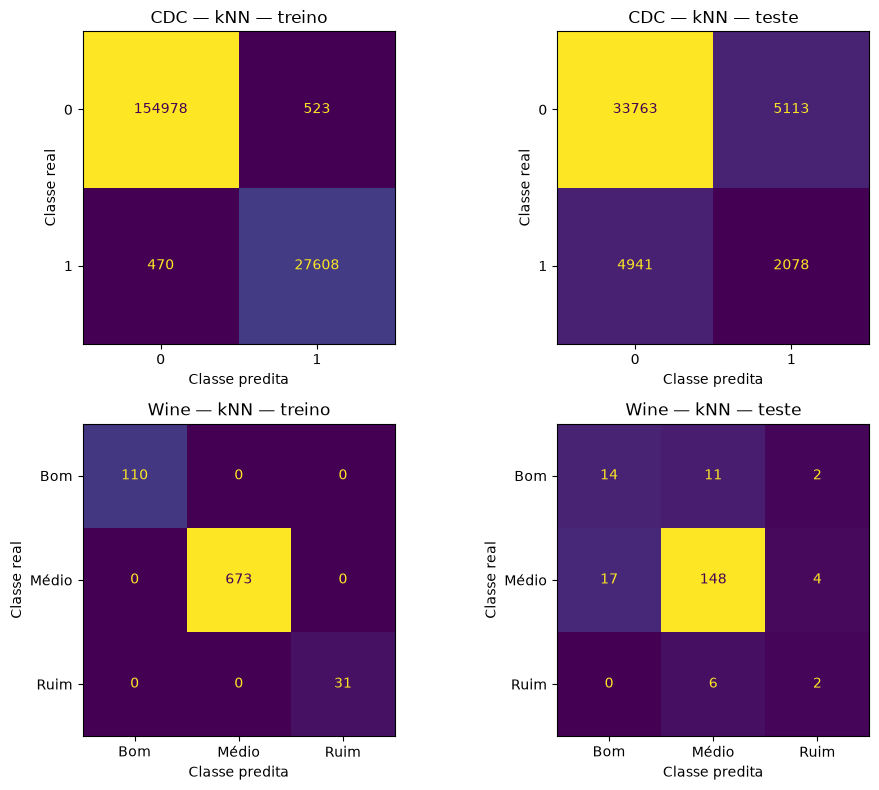

In [ ]:
resultados_knn = []
predicoes_knn = {}

for nome in ["CDC", "Wine"]:
    
    busca = buscas_knn[nome]

    for conjunto in ["treino", "teste"]:
        if conjunto == "treino":
            X_atual = dados_knn[nome][0]
            y_atual = dados_knn[nome][1]
        else:
            X_atual = dados_knn[nome][2]
            y_atual = dados_knn[nome][3]

        y_pred = busca.predict(X_atual)
        precisao, revocacao, f1, suporte = precision_recall_fscore_support(
            y_atual, y_pred, average="macro", zero_division=0
        )
        resultados_knn.append({
            "dataset": nome,
            "conjunto": conjunto,
            "acurácia": accuracy_score(y_atual, y_pred),
            "precisão macro": precisao,
            "revocação macro": revocacao,
            "F1 macro": f1,
        })
        predicoes_knn[(nome, conjunto)] = y_pred

tabela_knn = pd.DataFrame(resultados_knn)
display(tabela_knn.round(4))
print()

fig, eixos = plt.subplots(2, 2, figsize=(10, 8), squeeze=False)

for linha, nome in enumerate(["CDC", "Wine"]):
    busca = buscas_knn[nome]
    labels = busca.classes_

    for coluna, conjunto in enumerate(["treino", "teste"]):
        if conjunto == "treino":
            y_real = dados_knn[nome][1]
        else:
            y_real = dados_knn[nome][3]

        eixo = eixos[linha, coluna]
        y_pred = predicoes_knn[(nome, conjunto)]
        ConfusionMatrixDisplay.from_predictions(
            y_real, y_pred, labels=labels, ax=eixo, colorbar=False
        )
        eixo.set_title(f"{nome} — kNN — {conjunto}")
        eixo.set_xlabel("Classe predita")
        eixo.set_ylabel("Classe real")

        print(nome, conjunto)
        relatorio = classification_report(
            y_real, y_pred, labels=labels, output_dict=True, zero_division=0
        )
        tabela_relatorio = pd.DataFrame(relatorio).T
        display(tabela_relatorio.round(4))
        print()

fig.tight_layout()
plt.show()

### Discussão dos resultados

O melhor valor encontrado foi `k = 1` nos dois conjuntos. No CDC, a acurácia foi de 0,9946 e o F1 macro de 0,9896 no treino, enquanto no teste a acurácia foi de 0,7809 e o F1 macro de 0,5814. No Wine, a acurácia e o F1 macro foram iguais a 1,0000 no treino, enquanto no teste a acurácia foi de 0,8039 e o F1 macro de 0,5397. A queda entre treino e teste mostra que, com apenas um vizinho, o modelo praticamente memoriza o treino e apresenta overfiting.

# V. COMPARAÇÃO

Resultados no conjunto de teste:


,dataset,modelo,acurácia,precisão macro,revocação macro,F1 macro
0,CDC,SVM linear,0.6971,0.6269,0.7330,0.6171
1,CDC,SVM RBF,0.7014,0.6289,0.7358,0.6207
2,CDC,Regressão logística,0.7141,0.6300,0.7327,0.6277
3,CDC,kNN,0.7809,0.5807,0.5823,0.5814
4,Wine,SVM linear,0.5784,0.4692,0.6594,0.4565
5,Wine,SVM RBF,0.6961,0.4954,0.6567,0.5175
6,Wine,Regressão logística,0.5539,0.4741,0.6893,0.4519
7,Wine,kNN,0.8039,0.5329,0.5481,0.5397


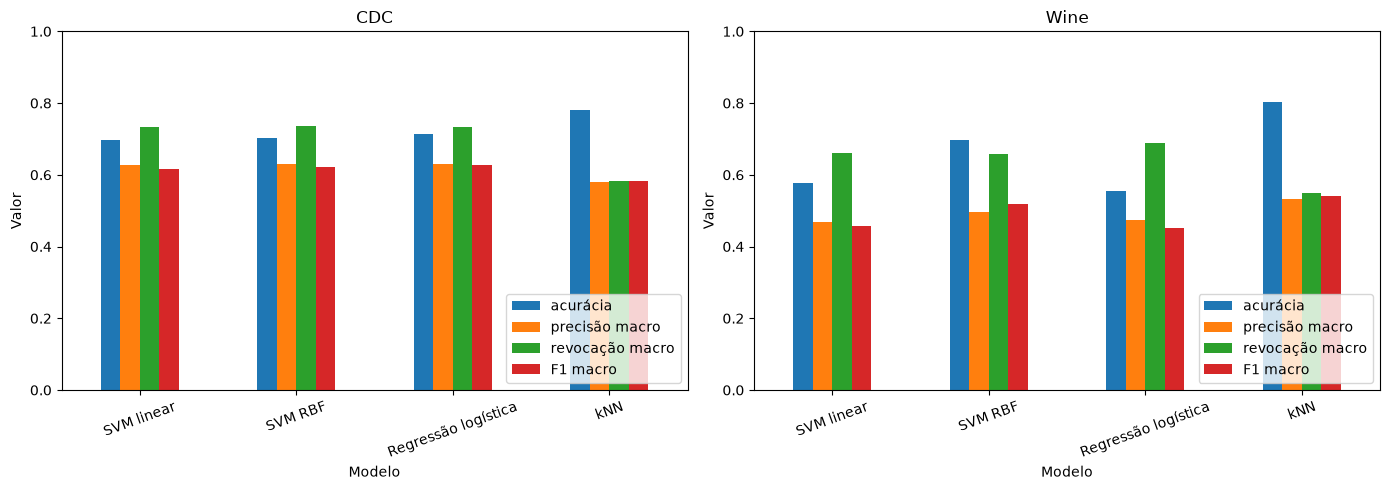

Resultados nos folds de validação:


,dataset,modelo,média F1 macro,desvio F1 macro,F1 macro (média ± desvio),limite inferior,limite superior
0,CDC,SVM linear,0.6140,0.0070,0.6140 ± 0.0070,0.6070,0.6211
1,CDC,SVM RBF,0.6264,0.0082,0.6264 ± 0.0082,0.6183,0.6346
2,CDC,Regressão logística,0.6252,0.0061,0.6252 ± 0.0061,0.6190,0.6313
3,CDC,kNN,0.5776,0.0221,0.5776 ± 0.0221,0.5556,0.5997
4,Wine,SVM linear,0.4522,0.0189,0.4522 ± 0.0189,0.4333,0.4711
5,Wine,SVM RBF,0.4800,0.0303,0.4800 ± 0.0303,0.4496,0.5103
6,Wine,Regressão logística,0.4546,0.0223,0.4546 ± 0.0223,0.4323,0.4770
7,Wine,kNN,0.4597,0.0508,0.4597 ± 0.0508,0.4089,0.5104


,dataset,maior média na validação,F1 macro do primeiro,segunda maior média,F1 macro do segundo,conclusão
0,CDC,SVM RBF,0.6264 ± 0.0082,Regressão logística,0.6252 ± 0.0061,A diferença não se destaca pelos intervalos.
1,Wine,SVM RBF,0.4800 ± 0.0303,kNN,0.4597 ± 0.0508,A diferença não se destaca pelos intervalos.


In [ ]:
# Primeiro, a comparação das métricas no conjunto de teste.
resultados_comparacao = []

for nome in ["CDC", "Wine"]:
    
    if nome == "CDC":
        y_real = y_cdc_test

    else:
        y_real = y_wine_test

    predicoes = {
        "SVM linear": predicoes_svm[(nome, "linear")],
        "SVM RBF": predicoes_svm[(nome, "rbf")],
        "Regressão logística": predicoes_logistica[nome],
        "kNN": predicoes_knn[(nome, "teste")],
    }

    for nome_modelo in predicoes:
        y_pred = predicoes[nome_modelo]
        precisao, revocacao, f1, suporte = precision_recall_fscore_support(
            y_real, y_pred, average="macro", zero_division=0
        )
        resultados_comparacao.append({
            "dataset": nome,
            "modelo": nome_modelo,
            "acurácia": accuracy_score(y_real, y_pred),
            "precisão macro": precisao,
            "revocação macro": revocacao,
            "F1 macro": f1,
        })

tabela_comparacao = pd.DataFrame(resultados_comparacao)
print("Resultados no conjunto de teste:")
display(tabela_comparacao.round(4))
print()

metricas = ["acurácia", "precisão macro", "revocação macro", "F1 macro"]
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), squeeze=False)

for coluna, nome in enumerate(["CDC", "Wine"]):
    eixo = eixos[0, coluna]
    mascara = tabela_comparacao["dataset"] == nome
    tabela_dataset = tabela_comparacao[mascara]
    tabela_dataset = tabela_dataset.set_index("modelo")
    tabela_dataset[metricas].plot(kind="bar", ax=eixo)
    eixo.set_title(nome)
    eixo.set_xlabel("Modelo")
    eixo.set_ylabel("Valor")
    eixo.set_ylim(0, 1)
    eixo.tick_params(axis="x", rotation=20)
    eixo.legend(loc="lower right")

fig.tight_layout()
plt.show()

# Agora, a média e o desvio do F1 macro nos cinco folds de validação.
resultados_validacao = []

for nome in ["CDC", "Wine"]:
    buscas = {
        "SVM linear": buscas_svm[(nome, "linear")],
        "SVM RBF": buscas_svm[(nome, "rbf")],
        "Regressão logística": buscas_logistica[nome],
        "kNN": buscas_knn[nome],
    }

    for nome_modelo in buscas:
        busca = buscas[nome_modelo]
        melhor_candidato = busca.best_index_
        notas_folds = []

        for fold in range(cv.n_splits):
            coluna_fold = f"split{fold}_test_score"
            nota = busca.cv_results_[coluna_fold][melhor_candidato]
            notas_folds.append(nota)

        media = np.mean(notas_folds)
        desvio = np.std(notas_folds, ddof=1)
        resultados_validacao.append({
            "dataset": nome,
            "modelo": nome_modelo,
            "média F1 macro": media,
            "desvio F1 macro": desvio,
            "F1 macro (média ± desvio)": f"{media:.4f} ± {desvio:.4f}",
            "limite inferior": media - desvio,
            "limite superior": media + desvio,
        })

tabela_validacao = pd.DataFrame(resultados_validacao)
print("Resultados nos folds de validação:")
display(tabela_validacao.round(4))
print()

# Conferir se os intervalos dos dois modelos com maior média se sobrepõem.
resultados_intervalos = []

for nome in ["CDC", "Wine"]:
    mascara = tabela_validacao["dataset"] == nome
    ordem = tabela_validacao[mascara]
    ordem = ordem.sort_values("média F1 macro", ascending=False)
    melhor = ordem.iloc[0]
    segundo = ordem.iloc[1]

    inicio_intersecao = max(melhor["limite inferior"], segundo["limite inferior"])
    fim_intersecao = min(melhor["limite superior"], segundo["limite superior"])

    if inicio_intersecao <= fim_intersecao:
        conclusao = "A diferença não se destaca pelos intervalos."
    else:
        conclusao = "A diferença se destaca pelos intervalos."

    resultados_intervalos.append({
        "dataset": nome,
        "maior média na validação": melhor["modelo"],
        "F1 macro do primeiro": melhor["F1 macro (média ± desvio)"],
        "segunda maior média": segundo["modelo"],
        "F1 macro do segundo": segundo["F1 macro (média ± desvio)"],
        "conclusão": conclusao,
    })

tabela_intervalos = pd.DataFrame(resultados_intervalos)
display(tabela_intervalos)

### Discussão dos resultados

Os modelos foram comparados no conjunto de teste usando acurácia, precisão, revocação e F1 macro. O F1 macro foi usado como principal medida por causa do desbalanceamento.

No CDC, a regressão logística teve o maior F1 macro no teste, de 0,6277, seguida pela SVM RBF, com 0,6207. O kNN teve acurácia maior, de 0,7809, mas F1 macro menor, de 0,5814. Nos folds, a SVM RBF teve média de 0,6264 ± 0,0082, enquanto a regressão logística teve 0,6252 ± 0,0061. Os intervalos de média menos desvio até média mais desvio se sobrepõem, então a diferença entre os dois modelos não é sigificativa nessa comparação.

No Wine, o kNN teve o maior F1 macro no teste, de 0,5397, seguido pela SVM RBF, com 0,5175. Nos folds, a SVM RBF teve a maior média, de 0,4800 ± 0,0303, seguida pelo kNN, com 0,4597 ± 0,0508. Os intervalos também se sobrepõem, então essa comparação também não mostra uma diferença significativa entre os dois modelos.

As médias e os desvios padrão amostrais foram calculados nos cinco folds de validação da melhor configuração de cada modelo.
